<a href="https://colab.research.google.com/github/y-adulyasak/SCOA_PhD/blob/main/S11_SPO/DFL_MILP_SPO_example_S1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MILP SPO+: supplier selection

**PhD Seminar: Smart-predict-then-optimize (SPO)** Companion to the workbooks (iteration 1 with Excel Solver, one sheet per week) and `DFL_MILP_SPO_example.xlsx` (all three iterations).
Runs in Colab: the MILP is a Pyomo model solved with HiGHS (both installed in the first code cell), plus NumPy, pandas and Matplotlib.

**MILP**: each supplier used in a week costs a
known fixed fee, so the buyer decides which suppliers to open and how to split the order.

$$\min_{w,\,y}\ \hat c^\top w + f^\top y \quad \\ \text{s.t.}\quad \textstyle\sum_j w_j = 1, \qquad \\  w_j \le u_j\,y_j, \forall j \qquad \\ y_j \in \{0,1\},\ w \ge 0.$$

Only the unit costs $\hat c$ are predicted; the fees $f$ are known. Three kinds of MILP appear in training:

| | cost vector | used for |
|---|---|---|
| MILP-c | true unit costs $c$ (+ fees) | the best plan in hindsight $w^*(c)$ and $z^*(c)$, once |
| MILP-ĉ | prediction $\hat c$ (+ fees) | the decision, to measure regret |
| MILP-SPO+ | $2\hat c - c$ (+ the same fees) | the SPO+ loss and its gradient |

$$\ell_{\text{SPO+}} = -\min_{w,y}\big[(2\hat c - c)^\top w + f^\top y\big] + 2\big[\hat c^\top w^*(c) + f^\top y^*(c)\big] - z^*(c),
\qquad \nabla_{\hat c}\,\ell_{\text{SPO+}} = 2\big(w^*(c) - w^*(2\hat c - c)\big).$$

In MILP-SPO+, we treat these costs $\hat{c}$ as part of the cost vector that we predict; then their
"training cost" for gradient calculations in SPO+ is $2f - f = f$. SPO+ is still convex as the max of a linear function over a finite set of plans equals
the max over their convex hull.

## 1. Setup

The MILP is a Pyomo model solved with HiGHS. Two functions are used everywhere below:

* `solve_milp(k)` returns the cheapest plan $(w, y)$ when the suppliers' unit costs are $k$.
* `cost(k, w, y)` $= \sum_j k_j w_j + \sum_j f_j y_j$ prices a plan $(w, y)$ at unit costs $k$.
* `plan(w)` only gives the plan a name (A–E, as on the slides) so that the tables are easy to read.

$k$ is the true $c$, the prediction $\hat c$ or $2\hat c - c$, depending on which MILP in the table above we need.

In [1]:
!pip install -q "pyomo>=6.9" highspy

In [2]:

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pyomo.environ as pyo
pd.set_option("display.precision", 3)
SOLVER = pyo.SolverFactory("highs")        # HiGHS: open-source LP/MIP solver, installed by highspy
assert SOLVER.available(), "HiGHS not found: run  !pip install -U pyomo highspy  and restart the runtime"
SOLVER.options["mip_rel_gap"] = 0          # solve every MILP to proven optimality (the default stops within 0.01%)

J   = [0, 1, 2]                            # supplier index j
SUP = ["S1 local", "S2 regional", "S3 overseas"]
U   = [0.6, 0.7, 1.0]                      # capacities, share of the order (overseas can cover it alone)
fee = [0.2, 0.2, 0.8]                      # known weekly fee if a supplier is used

x  = np.array([-0.4, -0.1, 0.1, 0.4])                      # freight index - 1, four past weeks
c  = np.array([[9.8, 8.2, 8.0], [10.0, 9.4, 8.9],          # true unit costs (observed after delivery)
               [10.0, 10.2, 9.5], [10.2, 11.4, 15.4]])      # week 4: port congestion surcharge on overseas

def solve_milp(k):
    """min   sum_j k_j w_j + sum_j fee_j y_j
       s.t.  sum_j w_j = 1,   w_j <= U_j y_j,   y_j in {0, 1},   0 <= w_j <= 1
    k: unit costs of the three suppliers (c, c_hat or 2c_hat - c). Returns the plan (w, y) as two lists."""
    m = pyo.ConcreteModel()
    m.w = pyo.Var(J, bounds=(0, 1))                        # share of the order given to supplier j
    m.y = pyo.Var(J, domain=pyo.Binary)                    # 1 if supplier j is used (its fee is paid)
    m.cost = pyo.Objective(expr=sum(float(k[j]) * m.w[j] + fee[j] * m.y[j] for j in J), sense=pyo.minimize)
    m.order = pyo.Constraint(expr=sum(m.w[j] for j in J) == 1)                  # the whole order is placed
    m.capacity = pyo.Constraint(J, rule=lambda m, j: m.w[j] <= U[j] * m.y[j])   # only used suppliers, up to capacity
    SOLVER.solve(m)
    w = [round(pyo.value(m.w[j]), 9) + 0.0 for j in J]     # round off solver noise such as 0.6000000001
    y = [round(pyo.value(m.y[j]), 9) + 0.0 for j in J]
    return w, y

def cost(k, w, y):
    "weekly cost of the plan (w, y) at unit costs k:  sum_j k_j w_j  +  sum_j fee_j y_j"
    purchase = sum(k[j] * w[j] for j in J)
    fees = sum(fee[j] * y[j] for j in J)
    return purchase + fees

# names for the plans that come up below, as on the slides (labels only: every plan is computed by the MILP)
PLAN_NAMES = {"A": [0, 0, 1],       # all from S3 overseas
              "B": [0.6, 0.4, 0],   # S1 full, the rest from S2
              "C": [0.3, 0.7, 0],   # S2 full, the rest from S1
              "D": [0.6, 0, 0.4],   # S1 full, the rest from S3
              "E": [0, 0.7, 0.3]}   # S2 full, the rest from S3
def plan(w):
    "the name of plan w, or its shares if it has no name"
    return next((n for n, p in PLAN_NAMES.items() if all(abs(w[j] - p[j]) < 1e-6 for j in J)), str(w))

w, y = solve_milp(c[0])                                    # example: week 1 at its true unit costs
print(f"week 1, cheapest plan {plan(w)}:  w = {w}   y = {y}")
print(f"  purchase = {sum(c[0][j] * w[j] for j in J):.2f}   fees = {sum(fee[j] * y[j] for j in J):.2f}   cost = {cost(c[0], w, y):.2f}")

week 1, cheapest plan A:  w = [0.0, 0.0, 1.0]   y = [0.0, 0.0, 1.0]
  purchase = 8.00   fees = 0.80   cost = 8.80


## 2. Data, MILP-c (once) and the least-squares start

In [3]:
best = [solve_milp(c[i]) for i in range(4)]                # MILP-c: best plan (w*, y*) in hindsight, week by week
z = np.array([cost(c[i], best[i][0], best[i][1]) for i in range(4)])   # z*(c): what that plan costs
print(pd.DataFrame({"x": x, "c1": c[:, 0], "c2": c[:, 1], "c3": c[:, 2],
                    "best plan": [plan(b[0]) for b in best], "z*(c)": z}, index=[1, 2, 3, 4]))
theta_ls = np.array([np.polyfit(x, c[:, j], 1)[::-1] for j in J])   # rows S1-S3: intercept, slope
print("\nleast squares, one line per supplier:")
for j in J: print(f"  {SUP[j]:12s} c_hat = {theta_ls[j, 0]:.3f} + {theta_ls[j, 1]:.3f} x")

     x    c1    c2    c3 best plan  z*(c)
1 -0.4   9.8   8.2   8.0         A   8.80
2 -0.1  10.0   9.4   8.9         A   9.70
3  0.1  10.0  10.2   9.5         A  10.30
4  0.4  10.2  11.4  15.4         B  11.08

least squares, one line per supplier:
  S1 local     c_hat = 10.000 + 0.471 x
  S2 regional  c_hat = 9.800 + 4.000 x
  S3 overseas  c_hat = 10.450 + 8.882 x


## 3. Iteration 1, step by step

One function evaluates a model θ on the four weeks: MILP-ĉ and MILP-SPO+ for each week, regret, SPO+ and the
gradient. Then we print each step as on the slides.

In [4]:
def predict(theta, xi):
    "predicted unit costs in a week with freight index xi:  c_hat_j = intercept_j + slope_j * xi"
    return np.array([theta[j][0] + theta[j][1] * xi for j in J])

def evaluate(theta):
    rows = []
    grad = np.zeros((3, 2))                                # mean SPO+ gradient: rows S1-S3, columns (intercept, slope)
    for i in range(4):
        w_best, y_best = best[i]                           # MILP-c, solved once in section 2
        c_hat = predict(theta, x[i])
        w2, y2 = solve_milp(c_hat)                         # MILP-ĉ: the decision
        k3 = 2*c_hat - c[i]; w3, y3 = solve_milp(k3)       # MILP-SPO+: inside SPO+ (same fees)
        max_term = -cost(k3, w3, y3)                       # -min[(2c_hat - c)'w + f'y]
        two = 2*cost(c_hat, w_best, y_best)                # 2[c_hat'w*(c) + f'y*(c)]
        g = np.array([2*(w_best[j] - w3[j]) for j in J]) + 0.0   # gradient w.r.t. the predicted unit costs
        for j in J:                                        # chain rule, since c_hat_j = intercept_j + slope_j * x:
            grad[j][0] += g[j] / 4                         #   d c_hat_j / d intercept_j = 1
            grad[j][1] += g[j] * x[i] / 4                  #   d c_hat_j / d slope_j     = x
        rows.append(dict(week=i + 1, x=x[i], c_hat=np.round(c_hat, 3), plan_2=plan(w2),
                         paid=cost(c[i], w2, y2), regret=round(cost(c[i], w2, y2) - z[i], 9) + 0.0,
                         k3=np.round(k3, 3), plan_3=plan(w3), max_term=max_term, two=two,
                         spo=round(max_term + two - z[i], 9) + 0.0, g=g, gx=np.round(g*x[i], 3) + 0.0))
    return pd.DataFrame(rows).set_index("week"), grad

T1, G1 = evaluate(theta_ls)
print("STEP 1: predict, solve MILP-ĉ, measure regret")
print(T1[["x", "c_hat", "plan_2", "paid", "regret"]].assign(best=[plan(b[0]) for b in best]))
print(f"mean regret {T1.regret.mean():.3f}")
c_hat = predict(theta_ls, x[1]); w2, y2 = solve_milp(c_hat); wb, yb = best[1]       # week 2: why the decision is wrong
print(f"\nweek 2 priced at c_hat:  MILP-ĉ's plan {plan(w2)} costs {cost(c_hat, w2, y2):.3f},  "
      f"the best plan in hindsight {plan(wb)} costs {cost(c_hat, wb, yb):.3f}")

STEP 1: predict, solve MILP-ĉ, measure regret
        x                   c_hat plan_2   paid  regret best
week                                                        
1    -0.4     [9.812, 8.2, 6.897]      A   8.80    0.00    A
2    -0.1     [9.953, 9.4, 9.562]      C   9.98    0.28    A
3     0.1  [10.047, 10.2, 11.338]      B  10.48    0.18    A
4     0.4  [10.188, 11.4, 14.003]      B  11.08    0.00    B
mean regret 0.115

week 2 priced at c_hat:  MILP-ĉ's plan C costs 9.966,  the best plan in hindsight A costs 10.362


In [5]:
print("STEP 2: MILP-SPO+ with unit costs 2c_hat - c (fees unchanged), and the loss")
print(T1[["k3", "plan_3", "max_term", "two"]].assign(z=z, spo=T1.spo, regret=T1.regret))
print(f"mean SPO+ {T1.spo.mean():.3f}   (SPO+ >= regret in every week: {bool((T1.spo >= T1.regret - 1e-9).all())})")
k3 = 2*predict(theta_ls, x[2]) - c[2]; w3, y3 = solve_milp(k3); wb, yb = best[2]   # week 3, priced at 2c_hat - c
print(f"\nweek 3 priced at 2c_hat - c:  MILP-SPO+'s plan {plan(w3)} costs {cost(k3, w3, y3):.3f} (= -max_term),  "
      f"the best plan in hindsight {plan(wb)} costs {cost(k3, wb, yb):.3f}")
print(f"the difference, {cost(k3, wb, yb) - cost(k3, w3, y3):.3f}, is week 3's SPO+ loss (best plan minus MILP-SPO+'s plan, both priced at 2c_hat - c)")

STEP 2: MILP-SPO+ with unit costs 2c_hat - c (fees unchanged), and the loss
                          k3 plan_3  max_term     two      z    spo  regret
week                                                                       
1        [9.824, 8.2, 5.794]      A    -6.594  15.394   8.80  0.000    0.00
2       [9.906, 9.4, 10.224]      C    -9.952  20.724   9.70  1.072    0.28
3     [10.094, 10.2, 13.176]      B   -10.536  24.276  10.30  3.440    0.18
4     [10.176, 11.4, 12.606]      B   -11.066  22.146  11.08  0.000    0.00
mean SPO+ 1.128   (SPO+ >= regret in every week: True)

week 3 priced at 2c_hat - c:  MILP-SPO+'s plan B costs 10.536 (= -max_term),  the best plan in hindsight A costs 13.976
the difference, 3.440, is week 3's SPO+ loss (best plan minus MILP-SPO+'s plan, both priced at 2c_hat - c)


In [6]:
print("STEP 3: gradients from the MILP solutions, g = 2(w*(c) - w*(2c_hat - c))")
print(T1[["plan_3", "g", "gx"]].assign(best=[plan(b[0]) for b in best]))
print("mean gradient: intercepts", np.round(G1[:, 0], 4), " slopes", np.round(G1[:, 1], 4))

STEP 3: gradients from the MILP solutions, g = 2(w*(c) - w*(2c_hat - c))
     plan_3                  g                   gx best
week                                                    
1         A    [0.0, 0.0, 0.0]      [0.0, 0.0, 0.0]    A
2         C  [-0.6, -1.4, 2.0]   [0.06, 0.14, -0.2]    A
3         B  [-1.2, -0.8, 2.0]  [-0.12, -0.08, 0.2]    A
4         B    [0.0, 0.0, 0.0]      [0.0, 0.0, 0.0]    B
mean gradient: intercepts [-0.45 -0.55  1.  ]  slopes [-0.015  0.015  0.   ]


In [7]:
eta = 0.75
theta_1 = theta_ls - eta * G1
print("STEP 4: update with eta = 0.75")
print(pd.DataFrame({"intercept before": theta_ls[:, 0], "intercept after": theta_1[:, 0],
                    "slope before": theta_ls[:, 1], "slope after": theta_1[:, 1]}, index=SUP).round(4))
T2, _ = evaluate(theta_1)
print("\ncosts used in iteration 2 and the new decisions:")
print(T2[["c_hat", "plan_2", "regret"]])
print(f"mean regret {T1.regret.mean():.3f} -> {T2.regret.mean():.3f}")

STEP 4: update with eta = 0.75
             intercept before  intercept after  slope before  slope after
S1 local                10.00           10.338         0.471        0.482
S2 regional              9.80           10.213         4.000        3.989
S3 overseas             10.45            9.700         8.882        8.882

costs used in iteration 2 and the new decisions:
                         c_hat plan_2  regret
week                                         
1       [10.145, 8.617, 6.147]      A    0.00
2       [10.289, 9.814, 8.812]      A    0.00
3     [10.386, 10.611, 10.588]      B    0.18
4      [10.53, 11.808, 13.253]      B    0.00
mean regret 0.115 -> 0.045


## 4. Three iterations

In [8]:
def train(theta0, eta, iterations=3):
    theta, hist = theta0.copy(), []
    for k in range(iterations + 1):
        T, G = evaluate(theta)
        hist.append(dict(iteration=k, intercepts=np.round(theta[:, 0], 3), slopes=np.round(theta[:, 1], 3),
                         plans=" ".join(T.plan_2), mean_spo=T.spo.mean(), mean_regret=T.regret.mean(),
                         spo_by_week=np.round(T.spo.values, 3)))
        theta = theta - (eta(k + 1) if callable(eta) else eta) * G
    return pd.DataFrame(hist).set_index("iteration")
H = train(theta_ls, 0.75)
print(H)

                        intercepts                 slopes    plans  mean_spo  \
iteration                                                                      
0               [10.0, 9.8, 10.45]    [0.471, 4.0, 8.882]  A C B B     1.128   
1            [10.338, 10.213, 9.7]  [0.482, 3.989, 8.882]  A A B B     0.301   
2          [10.563, 10.363, 9.325]  [0.504, 4.004, 8.845]  A A A B     0.284   
3          [10.563, 10.363, 9.325]  [0.437, 3.959, 8.957]  A A A B     0.258   

           mean_regret               spo_by_week  
iteration                                         
0                0.115   [0.0, 1.072, 3.44, 0.0]  
1                0.045    [0.0, 0.0, 1.205, 0.0]  
2                0.000  [0.0, 0.0, 0.053, 1.082]  
3                0.000  [0.0, 0.0, 0.087, 0.946]  


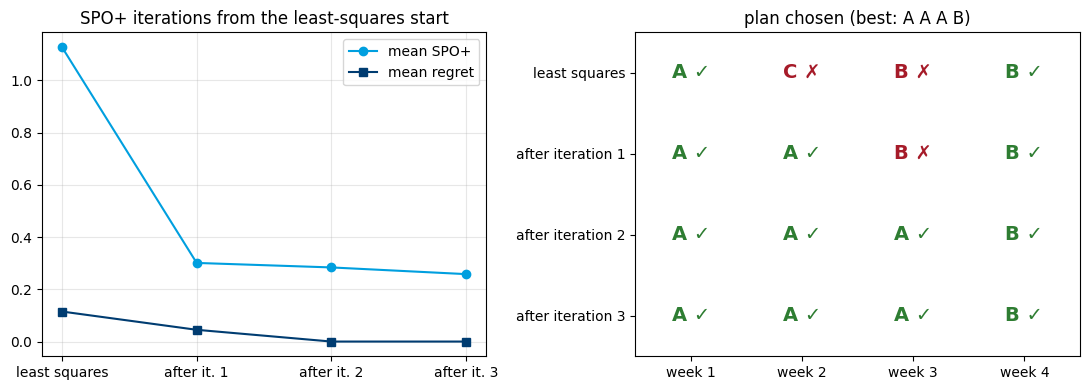

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(H.index, H.mean_spo, "-o", color="#009FDF", label="mean SPO+")
ax[0].plot(H.index, H.mean_regret, "-s", color="#003C71", label="mean regret")
ax[0].set_xticks(H.index, ["least squares", "after it. 1", "after it. 2", "after it. 3"]); ax[0].legend(); ax[0].grid(alpha=.3)
ax[0].set_title("SPO+ iterations from the least-squares start")
best_plans = [plan(b[0]) for b in best]
for r, p in enumerate(H.plans):
    for i, letter in enumerate(p.split()):
        ok = letter == best_plans[i]
        ax[1].text(i, -r, letter + (" ✓" if ok else " ✗"), ha="center", va="center", fontsize=14,
                   color="#2E7D32" if ok else "#A61B29", fontweight="bold")
ax[1].set_xlim(-0.5, 3.5); ax[1].set_ylim(-3.5, 0.5); ax[1].set_xticks(range(4), [f"week {i+1}" for i in range(4)])
ax[1].set_yticks([0, -1, -2, -3], ["least squares", "after iteration 1", "after iteration 2", "after iteration 3"]); ax[1].set_title("plan chosen (best: A A A B)")
plt.tight_layout(); plt.show()

## 5. Step size, starting point, and when to stop

* With η = 1 the iterations overshoot: week 3 stays wrong for five iterations.
* With η = 0.75 regret is zero after two iterations. Keep going and the mean SPO+ keeps falling, but at iteration 6 week 3
  flips back to plan B: SPO+ is a convex *surrogate*, and on four weeks lowering it can cost a decision (here it
  trades week 3's margin for week 4's). In practice, measure regret on held-out data and keep the best model.
* From flat quotes (no freight effect) the path is erratic.

SPO+ with a linear model is convex, so with diminishing step sizes every start reaches the same SPO+ optimum in the end;
a good start and a sensible step size decide how soon.

In [10]:
for name, th0, eta_ in [("least squares, eta 0.75", theta_ls, 0.75), ("least squares, eta 1.0", theta_ls, 1.0),
                        ("flat quotes, eta 0.75", np.array([[10.3, 0], [9.8, 0], [9.4, 0]]), 0.75)]:
    h = train(th0, eta_, iterations=8)
    print(f"{name}\n  mean SPO+   {np.round(h.mean_spo.values, 3)}\n  mean regret {np.round(h.mean_regret.values, 3)}")

least squares, eta 0.75
  mean SPO+   [1.128 0.301 0.284 0.258 0.233 0.207 0.181 0.156 0.13 ]
  mean regret [0.115 0.045 0.    0.    0.    0.    0.045 0.045 0.045]
least squares, eta 1.0
  mean SPO+   [1.128 0.275 0.241 0.207 0.173 0.16  0.373 0.172 0.328]
  mean regret [0.115 0.045 0.045 0.045 0.045 0.045 0.    0.045 0.   ]
flat quotes, eta 0.75
  mean SPO+   [1.47  1.346 1.293 1.623 1.429 1.112 1.067 1.042 1.016]
  mean regret [1.28 0.09 0.09 0.29 1.28 0.   0.   0.   0.  ]


## 6. Optional: a larger experiment, LP against MILP

100 training weeks and 3,000 test weeks from the same cost structure (with noise), repeated for three training
samples. The same linear model is trained with SPO+ from the least-squares start (200 subgradient steps, keeping the
model with the lowest training SPO+). We then compare four ways of deciding on the test weeks, for the LP (no fees)
and three fee levels of the MILP:

| approach | uses the freight index $x$? | costs handed to the LP/MILP for a test week |
|---|---|---|
| **Deterministic** | no | the mean costs of the 100 training weeks (the same every week) |
| **Least squares** (predict, then optimize) | yes | the least-squares line at $x$ |
| **SPO+** | yes | the SPO+ line at $x$ |
| **P2P with kNN** (Session 1), $k$ = 5 and 10 | yes | the mean costs of the $k$ training weeks with the closest $x$ |

In 6d the least-squares and SPO+ models also get a hinge feature. Every number below is the mean test regret, in % of
the mean optimal (hindsight) cost.

Each experiment needs about 30,000 MILP solves (MILP-SPO+ for every training week at every step, MILP-c and MILP-ĉ
for every test week), too many to build and solve a Pyomo model each time. So only here we exploit the structure of
the solution to speed things up: an optimal plan opens a set of suppliers and fills the cheapest of them first. With
these capacities only five sets can cover the order, so a small oracle tries each set and keeps the cheapest (this is
also what the Excel workbook does with formulas). The first cell checks the oracle against the Pyomo MILP; the
second runs every approach in every setting.

In [11]:
import itertools
def make_oracle(fees, integer):
    "fast exact solver for these capacities: try every set of suppliers that can cover the order, fill the cheapest first"
    subsets = [s for r in (1, 2, 3) for s in itertools.combinations(J, r) if sum(U[j] for j in s) >= 1]
    def fill(order):                                       # give each supplier in `order` as much as it can take
        w = [0.0, 0.0, 0.0]; left = 1.0
        for j in order: w[j] = min(U[j], left); left -= w[j]
        return w
    def solve(k):                                          # returns the plan w and the fees it pays
        if not integer:                                    # LP (no fees): fill the cheapest suppliers first
            return fill(sorted(J, key=lambda j: k[j])), 0.0
        best_v, best_w = None, None
        for s in subsets:                                  # MILP: try each set of suppliers, keep the cheapest
            w = fill(sorted(s, key=lambda j: k[j]))
            v = sum(k[j] * w[j] for j in J) + sum(fees[j] for j in J if w[j] > 1e-12)
            if best_v is None or v < best_v - 1e-12: best_v, best_w = v, w
        return best_w, sum(fees[j] for j in J if best_w[j] > 1e-12)
    return solve

# check: the oracle picks the same plan as the Pyomo MILP (the notebook's fees, 500 random cost vectors)
oracle, rng = make_oracle(fee, True), np.random.default_rng(0)
for _ in range(500):
    k = rng.uniform(5, 15, 3)
    w_milp, y_milp = solve_milp(k)
    w_fast, fees_fast = oracle(k)
    assert all(abs(w_milp[j] - w_fast[j]) < 1e-6 for j in J)
    assert abs(cost(k, w_milp, y_milp) - (sum(k[j] * w_fast[j] for j in J) + fees_fast)) < 1e-9
print("oracle and Pyomo MILP choose the same plan on 500 random cost vectors")

oracle and Pyomo MILP choose the same plan on 500 random cost vectors


In [12]:
def truth(xx): return np.c_[10 + 0.5*xx, 9.8 + 4*xx, 9.2 + 3*xx + 25*np.maximum(0, xx - 0.2)]

def knn_mean_costs(xs, cs, xq, k):
    "P2P with kNN: for each week in xq, the mean costs of the k training weeks with the closest freight index"
    out = []
    for xi in xq:
        nearest = np.argsort(np.abs(xs - xi), kind="stable")[:k]   # stable sort: ties go to the earlier week
        out.append([np.mean(cs[nearest, j]) for j in J])
    return out

def linear(xi): return [1.0, xi]                         # features: c_hat_j = theta_j0 + theta_j1 x
def hinge(xi): return [1.0, xi, max(0.0, xi - 0.2)]      #   ... + theta_j2 max(0, x - 0.2)   (used in 6d)

def experiment(fees, integer, seed, features=linear, steps=200):
    solve = make_oracle(fees, integer); r = np.random.default_rng(seed)
    xs = r.uniform(-0.5, 0.5, 100); cs = truth(xs) + r.normal(0, 0.2, (100, 3))
    r2 = np.random.default_rng(999); xt = r2.uniform(-0.5, 0.5, 3000); ct = truth(xt) + r2.normal(0, 0.2, (3000, 3))
    Fs = [features(xi) for xi in xs]; Ft = [features(xi) for xi in xt]; nf = len(Fs[0])   # feature vectors
    def predict_all(T, F): return [[sum(T[j][f] * Fi[f] for f in range(nf)) for j in J] for Fi in F]   # c_hat per week
    def total(k, w, f): return sum(k[j] * w[j] for j in J) + f                           # plan cost: purchase + fees
    W = [solve(cs[i]) for i in range(100)]; Z = [total(cs[i], *W[i]) for i in range(100)]
    Zt = [total(ct[i], *solve(ct[i])) for i in range(3000)]
    def test_regret(P):                       # P: costs handed to the solver for each test week
        return 100 * np.mean([total(ct[i], *solve(P[i])) - Zt[i] for i in range(3000)]) / np.mean(Zt)
    def spo_grad(T):
        P = predict_all(T, Fs); G = np.zeros((3, nf)); L = 0
        for i in range(100):
            k = [2*P[i][j] - cs[i][j] for j in J]; wt, ft = solve(k)              # MILP-SPO+
            L += -total(k, wt, ft) + 2*total(P[i], *W[i]) - Z[i]
            for j in J:
                g = 2*(W[i][0][j] - wt[j])
                for f in range(nf): G[j][f] += g * Fs[i][f]                    # chain rule: g times each feature
        return L / 100, G / 100

    # SPO+ training from the least-squares start, recording its progress
    T = np.linalg.lstsq(np.array(Fs), cs, rcond=None)[0].T; T_ls = T.copy()   # least-squares start, a row per supplier
    bestT = (spo_grad(T)[0], T.copy())
    checkpoints = {0, 1, 2, 5} | set(range(10, steps, 10))     # steps at which we also measure test regret
    curve = {"train_spo": [], "test_step": [], "test_regret": []}
    for k in range(1, steps + 1):
        L, G = spo_grad(T)                                     # T is the model after k - 1 steps
        curve["train_spo"].append(100 * L / np.mean(Z))        # mean training SPO+, % of the mean optimal cost
        if k - 1 in checkpoints:
            curve["test_step"].append(k - 1); curve["test_regret"].append(test_regret(predict_all(T, Ft)))
        if L < bestT[0]: bestT = (L, T.copy())
        T = T - 0.5/np.sqrt(k) * G

    mean_cost = [np.mean(cs[:, j]) for j in J]                 # deterministic: the same costs for every test week
    regret = {"Deterministic (mean cost)": test_regret([mean_cost] * 3000),
              "Least squares": test_regret(predict_all(T_ls, Ft)),
              "SPO+": test_regret(predict_all(bestT[1], Ft)),
              "P2P kNN, k=5": test_regret(knn_mean_costs(xs, cs, xt, 5)),
              "P2P kNN, k=10": test_regret(knn_mean_costs(xs, cs, xt, 10))}
    return regret, curve

SETTINGS = [("LP (no fees)", (0, 0, 0), False), ("MILP, fees 0.2/0.2/0.8", (0.2, 0.2, 0.8), True),
            ("MILP, fees 0.4/0.4/0.8", (0.4, 0.4, 0.8), True), ("MILP, fees 1.0/1.0/1.5", (1.0, 1.0, 1.5), True)]
REGRET, CURVE = {}, {}                                         # averaged over the three training samples
for label_, fees, integer in SETTINGS:
    runs = [experiment(fees, integer, s) for s in range(3)]
    REGRET[label_] = {m: np.mean([reg[m] for reg, _ in runs]) for m in runs[0][0]}
    CURVE[label_] = {key: np.mean([cur[key] for _, cur in runs], axis=0) for key in runs[0][1]}
    R = REGRET[label_]
    print(f"{label_:24s} test regret: least squares {R['Least squares']:.2f}%  SPO+ {R['SPO+']:.2f}%  "
          f"-> improved {100*(1 - R['SPO+']/R['Least squares']):.0f}%")

LP (no fees)             test regret: least squares 2.04%  SPO+ 0.83%  -> improved 59%
MILP, fees 0.2/0.2/0.8   test regret: least squares 0.98%  SPO+ 0.53%  -> improved 46%
MILP, fees 0.4/0.4/0.8   test regret: least squares 1.80%  SPO+ 0.46%  -> improved 75%
MILP, fees 1.0/1.0/1.5   test regret: least squares 2.05%  SPO+ 0.49%  -> improved 76%


### 6a. SPO+ training progress

Left: the mean SPO+ loss on the 100 training weeks after each subgradient step. Right: the regret of the current model
on the 3,000 test weeks (measured at steps 0, 1, 2, 5 and every 10 steps). Step 0 is the least-squares model.
Both are in % of the mean optimal cost, so the LP and the three MILPs share one scale.

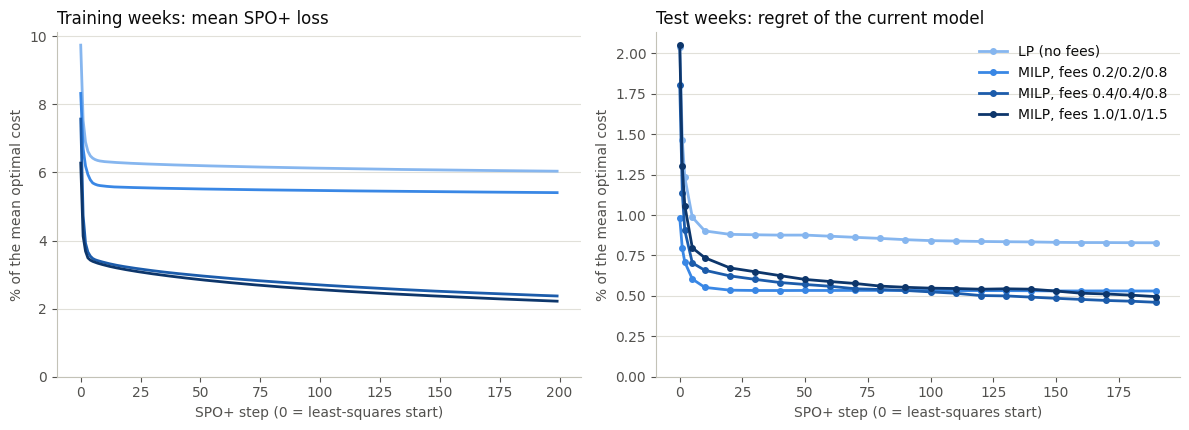

In [13]:
INK, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7"
SEQ = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]       # one blue, light to dark: no fees -> highest fees

def tidy_axes(a):
    a.grid(axis="y", color=GRID, lw=0.8); a.set_axisbelow(True)
    for side in ("top", "right"): a.spines[side].set_visible(False)
    for side in ("left", "bottom"): a.spines[side].set_color(AXIS)
    a.tick_params(colors=MUTED); a.yaxis.label.set_color(MUTED); a.xaxis.label.set_color(MUTED)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for (label_, _, _), colour in zip(SETTINGS, SEQ):
    cur = CURVE[label_]
    ax[0].plot(range(len(cur["train_spo"])), cur["train_spo"], color=colour, lw=2, label=label_)
    ax[1].plot(cur["test_step"], cur["test_regret"], "-o", color=colour, lw=2, ms=4, label=label_)
ax[0].set_title("Training weeks: mean SPO+ loss", loc="left", color=INK)
ax[1].set_title("Test weeks: regret of the current model", loc="left", color=INK)
for a in ax:
    tidy_axes(a); a.set_ylim(bottom=0)
    a.set_xlabel("SPO+ step (0 = least-squares start)"); a.set_ylabel("% of the mean optimal cost")
ax[1].legend(frameon=False, labelcolor=INK)
plt.tight_layout(); plt.show()

### 6b. Test weeks: deterministic (mean costs), least squares and SPO+, LP against MILP

The deterministic model ignores the freight index and hands the solver the mean training costs, so it picks the same
plan every week. Least squares and SPO+ use the same linear model at $x$; they differ only in the loss used to fit it.

test regret, % of the mean optimal cost
                        Deterministic (mean cost)  Least squares  SPO+
LP (no fees)                                 6.24           2.04  0.83
MILP, fees 0.2/0.2/0.8                       2.98           0.98  0.53
MILP, fees 0.4/0.4/0.8                       5.64           1.80  0.46
MILP, fees 1.0/1.0/1.5                       8.10           2.05  0.49



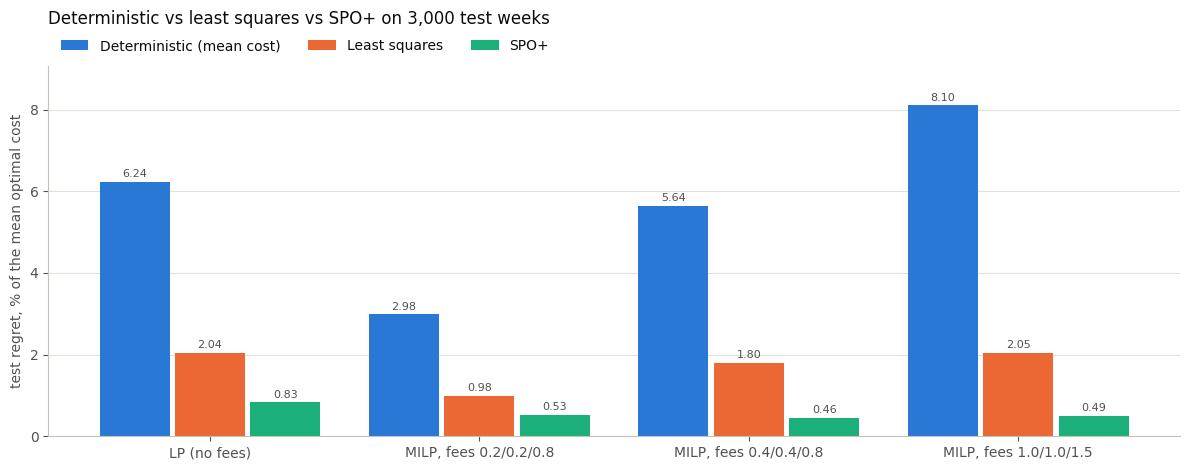

In [14]:
METHODS = ["Deterministic (mean cost)", "Least squares", "SPO+", "P2P kNN, k=5", "P2P kNN, k=10"]
COLOURS = dict(zip(METHODS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))   # a method keeps its colour
plt.rcParams["hatch.linewidth"] = 1.5                     # 6d: a hinge model = its method's colour with white stripes

def regret_bars(methods, title):
    table = pd.DataFrame(REGRET).T[methods]                 # rows: settings, columns: approaches
    print("test regret, % of the mean optimal cost\n" + table.round(2).to_string() + "\n")
    fig, ax = plt.subplots(figsize=(12, 4.8))
    width = 0.84 / len(methods)
    for m_i, m in enumerate(methods):
        pos = [g + (m_i - (len(methods) - 1) / 2) * width for g in range(len(table))]
        base = m.replace(" (hinge)", "")
        bars = ax.bar(pos, table[m], width=width - 0.02, color=COLOURS[base], label=m,
                      hatch="///" if m != base else None, edgecolor="white", linewidth=0)
        ax.bar_label(bars, labels=[f"{v:.2f}" for v in table[m]], padding=2, fontsize=8, color=MUTED)
    ax.set_xticks(range(len(table)), table.index, color=INK)
    ax.set_ylabel("test regret, % of the mean optimal cost"); ax.set_ylim(0, 1.12 * table.values.max())
    ax.set_title(title, loc="left", color=INK, pad=30)
    ax.legend(frameon=False, ncol=len(methods), loc="lower left", bbox_to_anchor=(0, 1.0), labelcolor=INK)
    tidy_axes(ax); plt.tight_layout(); plt.show()

regret_bars(METHODS[:3], "Deterministic vs least squares vs SPO+ on 3,000 test weeks")

### 6c. Adding P2P with kNN, k = 5 and k = 10

P2P as in Session 1: for a test week with freight index $x$, take the $k$ training weeks with the closest $x$ and
choose the plan that is cheapest on average over their observed costs (SAA over the neighbours). Because a plan's cost
is linear in the unit costs, that is the same as solving the MILP with the neighbours' mean costs, which is how the
code does it. The deterministic model is the extreme case $k = 100$: every training week gets the same weight.

test regret, % of the mean optimal cost
                        Deterministic (mean cost)  Least squares  SPO+  P2P kNN, k=5  P2P kNN, k=10
LP (no fees)                                 6.24           2.04  0.83          0.14           0.16
MILP, fees 0.2/0.2/0.8                       2.98           0.98  0.53          0.23           0.19
MILP, fees 0.4/0.4/0.8                       5.64           1.80  0.46          0.02           0.03
MILP, fees 1.0/1.0/1.5                       8.10           2.05  0.49          0.03           0.02



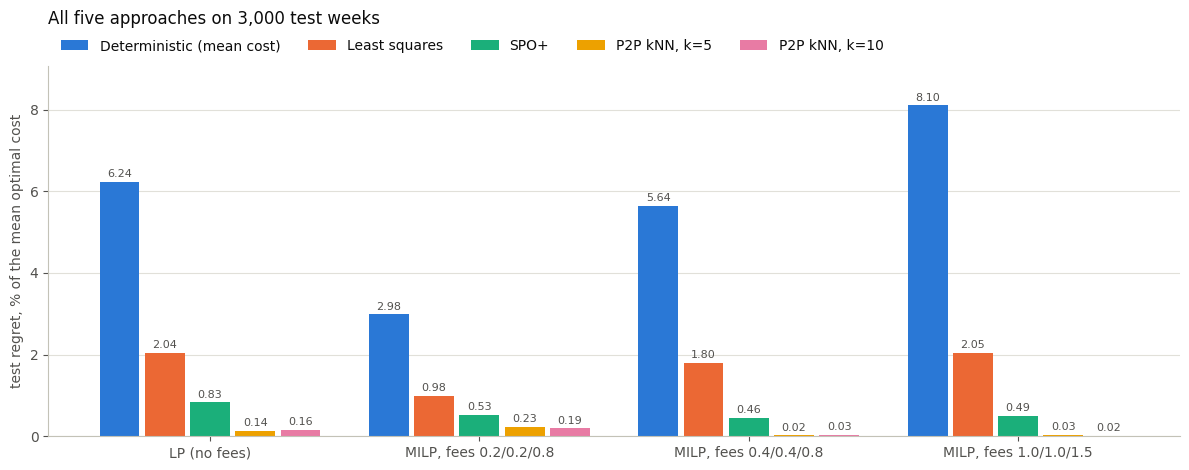

In [15]:
regret_bars(METHODS, "All five approaches on 3,000 test weeks")

### 6d. Giving the linear model a hinge feature

A straight line cannot follow the overseas surcharge, so give each supplier's line one more feature, a hinge at
$x = 0.2$:

$$\hat c_j = \theta_{j0} + \theta_{j1}\,x + \theta_{j2}\max(0,\ x - 0.2).$$

The model is still linear in $\theta$, so nothing else changes: least squares now fits three coefficients per supplier,
and SPO+ trains them exactly as before (the gradient for $\theta_{j2}$ is $g_j \max(0, x - 0.2)$). The training weeks,
test weeks, seeds and steps are the same as above; only the features change.

This is a best case: the hinge sits exactly where the true cost bends. Without that knowledge one would use several
hinges (a spline), a tree or a neural network.

test regret, % of the mean optimal cost
                        Least squares  Least squares (hinge)  SPO+  SPO+ (hinge)  P2P kNN, k=5  P2P kNN, k=10
LP (no fees)                     2.04                   0.11  0.83          0.12          0.14           0.16
MILP, fees 0.2/0.2/0.8           0.98                   0.17  0.53          0.17          0.23           0.19
MILP, fees 0.4/0.4/0.8           1.80                   0.01  0.46          0.01          0.02           0.03
MILP, fees 1.0/1.0/1.5           2.05                   0.01  0.49          0.01          0.03           0.02



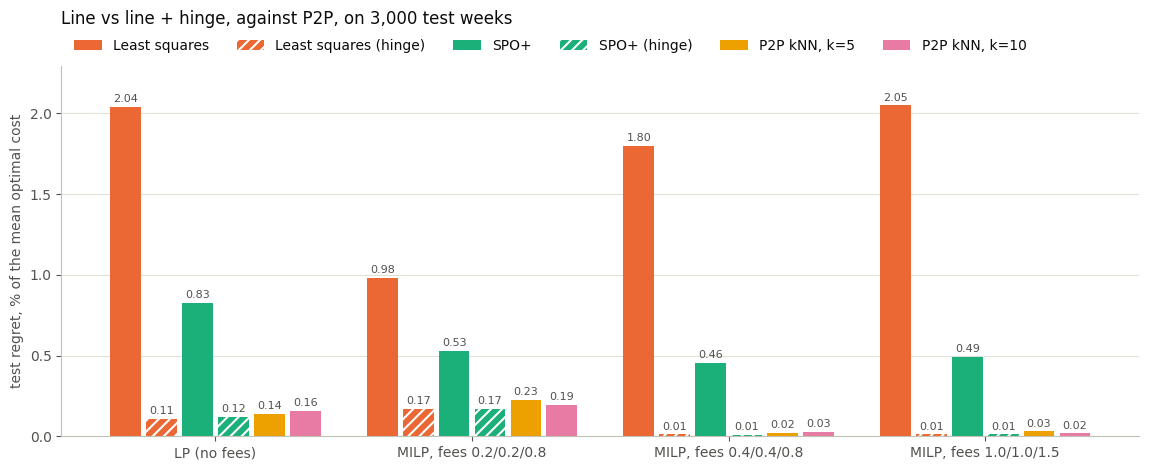

In [16]:
for label_, fees, integer in SETTINGS:                     # same weeks and seeds; the model now has a hinge
    runs = [experiment(fees, integer, s, features=hinge) for s in range(3)]
    for m in ("Least squares", "SPO+"):
        REGRET[label_][m + " (hinge)"] = np.mean([reg[m] for reg, _ in runs])

regret_bars(["Least squares", "Least squares (hinge)", "SPO+", "SPO+ (hinge)", "P2P kNN, k=5", "P2P kNN, k=10"],
            "Line vs line + hinge, against P2P, on 3,000 test weeks")

**Reading the results**

* **Most of the SPO+ gain comes in the first few steps (6a).** One subgradient step removes about half of the test-regret
  gap between least squares and the final SPO+ model, five steps about 80–90%. For the LP and the small fees the test
  regret is flat after about 10 steps; with the larger fees it keeps improving slowly over all 200 steps, together
  with the training loss.
* **Using the freight index matters most, then the loss (6b).** The deterministic plan ignores $x$ and pays 3–8% regret.
  The least-squares line cuts that to 1–2%, and fitting the same line with SPO+ removes another half to three quarters,
  most with the larger fees, where each wrong plan also pays fees.
* **P2P beats the straight lines (6c).** The overseas cost bends sharply above $x = 0.2$ (the congestion surcharge), and
  no straight line can follow that bend, whatever loss it is fitted with: SPO+ finds the best line *for the decision*,
  but it is still a line. With a single feature and 100 weeks, the 5 or 10 nearest weeks have almost the same $x$ and
  the noise is small, so their mean costs track the bend. The ranking can flip when there are many features or few
  weeks (the nearest weeks are then far away), or when the model can represent the bend (6d).
* **With the hinge, least squares also catches up.** Once the model can represent the true
  expected costs, least squares alone brings the test regret to the P2P level or slightly below (0.01–0.17%), and SPO+
  ends within 0.01 points of it (slightly worse in the LP). SPO+ helps most when the model is misspecified: the loss
  then decides which errors the model makes, and SPO+ picks the errors that change the fewest decisions. When the model
  can represent the costs, fitting them accurately already gives near-optimal decisions. SPO+ improves the decisions
  of a model class; it cannot fix a model class that cannot represent the costs.

## Exercises

1. **Fees.** Raise the overseas fee to 1.2. Which weeks change their best plan? Does least squares still decide
   wrongly, and how many SPO+ iterations are needed now?
2. **LP relaxation.** Replace MILP-SPO+ by its LP relaxation (in `solve_milp`, declare `m.y` with `bounds=(0, 1)` instead of `domain=pyo.Binary`, for MILP-SPO+ only). Does training still fix weeks 2 and 3? You can see why the relaxation a common shortcut in practice to spped
